# Task 5 — Avaliação detalhada do modelo final no teste

Este notebook faz a parte quantitativa da Task 5: **métricas adicionais** (balanced accuracy e MCC), **desempenho por grupos operacionais** (distritos, localizações e postos) e **análise de erros** (que falhas o modelo deixa passar e que alertas dá em vão).

**O teste não é reavaliado.** O modelo final foi treinado e avaliado uma única vez no caderno da Task 4 (secção 11), e as suas previsões ficaram guardadas em `Resultados/task4_teste_previsoes.csv.gz`. Aqui **não se treina nada**: lê-se esse ficheiro e juntam-se, sessão a sessão, as colunas do conjunto de dados (posto, distrito, causa de fim, histórico). Nenhuma decisão do modelo, das variáveis, dos hiperparâmetros ou do limiar pode ser alterada por causa do que se vê aqui.

**Antes de correr** é preciso ter na pasta `Resultados/`:
- `task4_teste_previsoes.csv.gz` (data, alvo, score e alerta do teste, gerado pelo caderno da Task 4);
- `task4_limiar.json` (limiar fixo complementar, fixado antes de abrir o teste).

| Secção | O que responde |
|---|---|
| 0 | Configuração e dados |
| 1 | As decisões que se avaliam (modelo final e baselines) |
| 2 | Métricas completas, incluindo balanced accuracy e MCC |
| 3 | Desempenho por distrito e por localização |
| 4 | Desempenho por posto |
| 5 | Análise de erros: falhas não detetadas e falsos alertas |
| 6 | Valor operacional por decis de risco |
| 7 | Ficheiros guardados para o relatório |

## 0. Configuração e dados

In [30]:
import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score, matthews_corrcoef

import ablacao as ab
import avaliacao as av

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)

DATA_PATH = Path("Charging_Data_educational.csv")
PASTA = Path("Resultados")
PREVISOES = PASTA / "task4_teste_previsoes.csv.gz"
LIMIAR_JSON = PASTA / "task4_limiar.json"

INICIO_TESTE, FIM_TESTE = pd.Timestamp("2021-10-01"), pd.Timestamp("2022-01-01")
X_ALERTAS, JANELA = 200, 7           # orçamento de alertas por 1000 sessões e janela do limiar móvel (secção 8.8)
MIN_SESSOES_POSTO = 200              # postos com menos sessões no teste ficam fora das tabelas de ordenação
VERIFICAR_TABELA_55 = True           # compara com a Tabela 55 do relatório (só faz sentido com o teste verdadeiro)

import time
T_INICIO = time.perf_counter()      # para medir o tempo total do caderno (secção 11)

In [31]:
def carregar_tudo(caminho):
    """Igual à do caderno da Task 4 (secção 11): como ab.carregar_dev, mas sem remover o teste."""
    d = pd.read_csv(caminho, parse_dates=["Start Time"])
    d.columns = d.columns.str.strip()
    d["end_cause"] = d["end_cause"].str.strip()
    d["is_Abnormal"] = (~d["end_cause"].isin(ab.NORMAL_CAUSES)).astype(int)
    d = d.sort_values("Start Time", kind="stable").reset_index(drop=True)
    d["hour"] = d["Start Time"].dt.hour
    d["dow"] = d["Start Time"].dt.dayofweek
    for ent, a, b in [("post", "post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal"),
                      ("user", "user_days_since_previous_completed_session", "user_days_since_previous_completed_abnormal")]:
        d[f"{ent}_last_completed_abnormal"] = np.isclose(d[a], d[b]).astype(int)
    return d


tudo = carregar_tudo(DATA_PATH)
for c in ["Location Information", "District Name", "Charging Post ID"]:      # só para esta análise: tirar espaços e tabulações
    tudo[c] = tudo[c].astype(str).str.strip()
dev_final = tudo[tudo["Start Time"] < INICIO_TESTE].reset_index(drop=True)
teste = tudo[(tudo["Start Time"] >= INICIO_TESTE) & (tudo["Start Time"] < FIM_TESTE)].reset_index(drop=True)

# previsões guardadas pelo caderno da Task 4: têm de corresponder, linha a linha, às sessões do teste
prev = pd.read_csv(PREVISOES, parse_dates=["Start Time"])
assert len(prev) == len(teste), f"o ficheiro tem {len(prev)} linhas e o teste {len(teste)}"
assert (prev["Start Time"].to_numpy() == teste["Start Time"].to_numpy()).all(), "as datas não coincidem: ordem diferente"
assert (prev["is_Abnormal"].to_numpy() == teste["is_Abnormal"].to_numpy()).all(), "o alvo não coincide"
teste["score"] = prev["score"].to_numpy()
teste["alerta"] = prev["alerta"].to_numpy().astype(int)
y_t, s_t = teste["is_Abnormal"].to_numpy().astype(int), teste["score"].to_numpy()

with open(LIMIAR_JSON, encoding="utf-8") as fh:
    LIMIAR_COMPL = json.load(fh)["limiar_fixo_complementar"]

print(f"desenvolvimento: {len(dev_final):,} sessões | teste: {len(teste):,} sessões "
      f"({teste['Start Time'].min():%Y-%m-%d} a {teste['Start Time'].max():%Y-%m-%d}), prevalência {y_t.mean():.1%}")
print(f"previsões alinhadas com o teste | limiar fixo complementar {LIMIAR_COMPL:.4f}")

desenvolvimento: 360,996 sessões | teste: 80,081 sessões (2021-10-01 a 2021-12-31), prevalência 17.6%
previsões alinhadas com o teste | limiar fixo complementar 0.3328


## 1. As decisões que se avaliam

São as mesmas da Tabela 55 do relatório, construídas **sem treinar nada**:

- **Random Forest, limiar móvel de 7 dias (principal):** os alertas vêm do ficheiro guardado.
- **Random Forest, limiar fixo complementar** (0,3328) **e limiar 0,5:** aplicados ao score guardado.
- **Random Forest, orçamento exato (referência):** as 200 sessões em cada 1000 com maior score, comparável com o recall dos folds.
- **Baselines:** a taxa de falhas do posto nos últimos 7 dias (mesmo limiar móvel e orçamento exato) e a última sessão do posto anómala (orçamento exato e regra pura). Não precisam de treino: são colunas do conjunto de dados.

In [32]:
col7 = "post_previous_abnormal_rate_7D"
taxa_t = teste[col7].to_numpy()
ultima_t = teste["post_last_completed_abnormal"].to_numpy().astype(float)

# limiar móvel da baseline "taxa do posto a 7 dias": precisa dos 7 dias de desenvolvimento antes do teste
aq = dev_final[dev_final["Start Time"] >= INICIO_TESTE - pd.Timedelta(days=JANELA)]
bloco = pd.concat([aq, teste[dev_final.columns.intersection(teste.columns)]], ignore_index=True)
_, pred_taxa_movel, _ = av.alertas_limiar_movel(bloco["Start Time"], bloco[col7].to_numpy(),
                                                INICIO_TESTE, FIM_TESTE, X_ALERTAS, JANELA)

decisoes = {   # nome: (score, alertas)
    "RF: limiar móvel de 7 dias (principal)": (s_t, teste["alerta"].to_numpy()),
    f"RF: limiar fixo complementar ({LIMIAR_COMPL:.4f})": (s_t, (s_t >= LIMIAR_COMPL).astype(int)),
    "RF: limiar 0,5": (s_t, (s_t >= 0.5).astype(int)),
    "RF: orçamento exato (referência)": (s_t, av.alertas_por_orcamento(s_t, X_ALERTAS)),
    "Taxa do posto 7 dias: limiar móvel": (taxa_t, pred_taxa_movel),
    "Taxa do posto 7 dias: orçamento exato": (taxa_t, av.alertas_por_orcamento(taxa_t, X_ALERTAS)),
    "Última sessão anómala: orçamento exato": (ultima_t, av.alertas_por_orcamento(ultima_t, X_ALERTAS)),
    "Última sessão anómala: regra pura": (ultima_t, (ultima_t >= 1).astype(int)),
}
NOME_RF = "RF: limiar móvel de 7 dias (principal)"
NOME_BASE = "Taxa do posto 7 dias: limiar móvel"
pred_rf = decisoes[NOME_RF][1].astype(int)
pred_base = decisoes[NOME_BASE][1].astype(int)
print({n: int(p.sum()) for n, (s, p) in decisoes.items()})

{'RF: limiar móvel de 7 dias (principal)': 15645, 'RF: limiar fixo complementar (0.3328)': 11227, 'RF: limiar 0,5': 5717, 'RF: orçamento exato (referência)': 16016, 'Taxa do posto 7 dias: limiar móvel': 15418, 'Taxa do posto 7 dias: orçamento exato': 16016, 'Última sessão anómala: orçamento exato': 16016, 'Última sessão anómala: regra pura': 14091}


## 2. Métricas completas, incluindo balanced accuracy e MCC

As duas métricas novas pedidas pelo enunciado, e o que cada uma mede neste problema:

- **Balanced accuracy** = (recall + especificidade) / 2. Dá o mesmo peso às duas classes, por isso não se deixa enganar pela maioria de sessões normais. Um modelo que não alerta nunca (ou que alerta ao acaso) fica em **0,5**.
- **MCC** (coeficiente de correlação de Matthews) resume as quatro células da matriz de confusão num só valor entre −1 e 1. Fica em **0** para um alerta aleatório, e só é alto se o modelo acertar nas duas classes.

Ambas dependem do limiar e do número de alertas, por isso são calculadas para cada decisão da secção 1. A PR-AUC (simples e normalizada) e a ROC-AUC não dependem do limiar.

In [33]:
def metricas(y, score, pred):
    """Métricas de decisão (dependem dos alertas), operacionais (por 1000 sessões) e de ordenação."""
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(int); score = np.asarray(score, dtype=float)
    n = len(y)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    rec = tp / (tp + fn) if tp + fn else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    esp = tn / (tn + fp) if tn + fp else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (tp + fp) and (prec + rec) > 0 else 0.0
    mcc = matthews_corrcoef(y, pred) if 0 < pred.sum() < n and 0 < y.sum() < n else 0.0
    prev = y.mean()
    com_duas_classes = 0 < y.sum() < n
    pr = average_precision_score(y, score) if com_duas_classes else np.nan
    return {"sessões": n, "prevalência": prev, "alertas/1000": 1000 * (tp + fp) / n,
            "precisão": prec, "recall": rec, "F1": f1,
            "balanced accuracy": (rec + esp) / 2, "MCC": mcc,
            "PR-AUC": pr, "PR-AUC norm.": (pr - prev) / (1 - prev) if com_duas_classes else np.nan,
            "ROC-AUC": roc_auc_score(y, score) if com_duas_classes else np.nan,
            "corretos/1000": 1000 * tp / n, "falsos/1000": 1000 * fp / n, "falhados/1000": 1000 * fn / n}


tabela = pd.DataFrame({n: metricas(y_t, s, p) for n, (s, p) in decisoes.items()}).T
tabela.round(3)

,sessões,prevalência,alertas/1000,precisão,recall,F1,balanced accuracy,MCC,PR-AUC,PR-AUC norm.,ROC-AUC,corretos/1000,falsos/1000,falhados/1000
RF: limiar móvel de 7 dias (principal),80081.0,0.176,195.365,0.468,0.520,0.493,0.697,0.379,0.536,0.437,0.793,91.520,103.845,84.402
RF: limiar fixo complementar (0.3328),80081.0,0.176,140.196,0.545,0.434,0.484,0.679,0.392,0.536,0.437,0.793,76.423,63.773,99.499
"RF: limiar 0,5",80081.0,0.176,71.390,0.697,0.283,0.402,0.628,0.379,0.536,0.437,0.793,49.750,21.641,126.172
RF: orçamento exato (referência),80081.0,0.176,199.998,0.466,0.530,0.496,0.700,0.381,0.536,0.437,0.793,93.268,106.729,82.654
Taxa do posto 7 dias: limiar móvel,80081.0,0.176,192.530,0.388,0.425,0.406,0.641,0.272,0.381,0.249,0.723,74.749,117.781,101.173
Taxa do posto 7 dias: orçamento exato,80081.0,0.176,199.998,0.386,0.439,0.411,0.645,0.276,0.381,0.249,0.723,77.222,122.776,98.700
Última sessão anómala: orçamento exato,80081.0,0.176,199.998,0.389,0.442,0.414,0.647,0.280,0.282,0.129,0.652,77.821,122.176,98.101
Última sessão anómala: regra pura,80081.0,0.176,175.959,0.426,0.426,0.426,0.652,0.303,0.282,0.129,0.652,74.937,101.023,100.985


In [34]:
# Confere com a Tabela 55 do relatório (valores do caderno da Task 4)? Só tem sentido com o teste verdadeiro.
if VERIFICAR_TABELA_55:
    esperado = {   # (decisão, métrica): valor na Tabela 55
        (NOME_RF, "alertas/1000"): 195, (NOME_RF, "precisão"): 0.468, (NOME_RF, "recall"): 0.520, (NOME_RF, "F1"): 0.493,
        (NOME_RF, "corretos/1000"): 91.5, (NOME_RF, "falsos/1000"): 103.8, (NOME_RF, "falhados/1000"): 84.4,
        (NOME_RF, "PR-AUC norm."): 0.437, (NOME_RF, "ROC-AUC"): 0.793,
        ("RF: limiar 0,5", "recall"): 0.283, ("RF: orçamento exato (referência)", "recall"): 0.530,
        (NOME_BASE, "recall"): 0.425, (NOME_BASE, "PR-AUC norm."): 0.249,
        ("Última sessão anómala: orçamento exato", "recall"): 0.442}
    tol = {"alertas/1000": 1.0, "corretos/1000": 0.1, "falsos/1000": 0.1, "falhados/1000": 0.1}
    ok = True
    for (n, m), v in esperado.items():
        obtido = tabela.loc[n, m]
        bom = abs(obtido - v) <= tol.get(m, 0.0015)
        ok &= bom
        if not bom:
            print(f"DIFERENTE: {n} | {m}: obtido {obtido:.3f}, Tabela 55 {v}")
    print("Confere com a Tabela 55." if ok else "ATENÇÃO: há diferenças em relação à Tabela 55 (ver acima).")

Confere com a Tabela 55.


In [35]:
# Vista compacta para o relatório: modelo final contra as duas baselines, com o mesmo procedimento de limiar
principais = [NOME_RF, f"RF: limiar fixo complementar ({LIMIAR_COMPL:.4f})", "RF: limiar 0,5",
              NOME_BASE, "Última sessão anómala: regra pura"]
tabela.loc[principais, ["alertas/1000", "precisão", "recall", "F1", "balanced accuracy", "MCC",
                        "PR-AUC", "PR-AUC norm.", "corretos/1000", "falsos/1000", "falhados/1000"]].round(3)

,alertas/1000,precisão,recall,F1,balanced accuracy,MCC,PR-AUC,PR-AUC norm.,corretos/1000,falsos/1000,falhados/1000
RF: limiar móvel de 7 dias (principal),195.365,0.468,0.520,0.493,0.697,0.379,0.536,0.437,91.520,103.845,84.402
RF: limiar fixo complementar (0.3328),140.196,0.545,0.434,0.484,0.679,0.392,0.536,0.437,76.423,63.773,99.499
"RF: limiar 0,5",71.390,0.697,0.283,0.402,0.628,0.379,0.536,0.437,49.750,21.641,126.172
Taxa do posto 7 dias: limiar móvel,192.530,0.388,0.425,0.406,0.641,0.272,0.381,0.249,74.749,117.781,101.173
Última sessão anómala: regra pura,175.959,0.426,0.426,0.426,0.652,0.303,0.282,0.129,74.937,101.023,100.985


**Conclusão.** Com o limiar móvel de 7 dias, o modelo final obtém uma balanced accuracy de 0,697 e um MCC de 0,379, contra 0,5 e 0 para um alerta aleatório, e uma PR-AUC de 0,536, contra uma prevalência de 0,176. Com um número de alertas semelhante, supera a taxa do posto a 7 dias (0,641; 0,272; 0,381) e a regra da última sessão anómala (0,652; 0,303; 0,282): mais 0,056 e 0,045 de balanced accuracy, e mais 0,107 e 0,076 de MCC. O limiar 0,5 fica claramente atrás pela balanced accuracy (0,628), porque deteta só 28% das falhas. As duas métricas ordenam os limiares do modelo de forma diferente: o limiar móvel tem a maior balanced accuracy (0,697) e o limiar fixo de 0,333 tem o maior MCC (0,392), porque emite menos alertas e com maior precisão. A diferença vem de as métricas ponderarem de forma diferente os dois erros. O limiar foi escolhido pela capacidade de resposta (200 alertas por 1000 sessões) antes de abrir o teste, e não é alterado.

## 3. Desempenho por distrito e por localização

O limiar é o mesmo para todo o teste (o do modelo final), por isso cada grupo recebe os alertas que os seus scores determinam. Mede-se o recall e a precisão em cada grupo, com **intervalo de confiança de 95%** para o recall (método de Wilson), e compara-se com a baseline da taxa do posto a 7 dias.

Os grupos com poucas falhas têm intervalos largos: uma diferença entre dois grupos só conta se os intervalos não se sobrepuserem muito.

In [36]:
def wilson(k, n, z=1.96):
    """Intervalo de confiança de 95% (Wilson) para uma proporção k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n; den = 1 + z * z / n
    centro = (p + z * z / (2 * n)) / den
    meia = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centro - meia, centro + meia


FP_TOTAL = int(((pred_rf == 1) & (y_t == 0)).sum())
FN_TOTAL = int(((pred_rf == 0) & (y_t == 1)).sum())
ALERTAS_TOTAL = int(pred_rf.sum())


def por_grupo(rotulos, ordem=None, min_sessoes=1):
    """Uma linha por grupo: o modelo final e a baseline, com os alertas do limiar global."""
    r = pd.Series(np.asarray(rotulos, dtype=object))
    grupos = ordem if ordem is not None else sorted(r.dropna().unique(), key=str)
    linhas = {}
    for g in grupos:
        m = (r == g).to_numpy()
        if m.sum() < min_sessoes:
            continue
        yy, pp, pb = y_t[m], pred_rf[m], pred_base[m]
        tp = int(((pp == 1) & (yy == 1)).sum()); fp = int(((pp == 1) & (yy == 0)).sum())
        fn = int(((pp == 0) & (yy == 1)).sum()); n_fal = int(yy.sum())
        lo, hi = wilson(tp, n_fal)
        linhas[g] = {"sessões": int(m.sum()), "% das sessões": m.mean(), "falhas": n_fal, "prevalência": yy.mean(),
                     "% dos alertas": pp.sum() / ALERTAS_TOTAL, "alertas/1000": 1000 * pp.mean(),
                     "precisão": tp / (tp + fp) if tp + fp else np.nan,
                     "recall": tp / n_fal if n_fal else np.nan, "IC95% inf.": lo, "IC95% sup.": hi,
                     "recall baseline": ((pb == 1) & (yy == 1)).sum() / n_fal if n_fal else np.nan,
                     "% dos falsos alertas": fp / FP_TOTAL, "% das falhas não detetadas": fn / FN_TOTAL}
    t = pd.DataFrame(linhas).T
    t["dif. recall (modelo − baseline)"] = t["recall"].astype(float) - t["recall baseline"].astype(float)
    return t


dist = por_grupo(teste["District Name"].to_numpy())
dist.round(3)

,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,IC95% inf.,IC95% sup.,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
Nanhu,10891.0,0.136,2598.0,0.239,0.206,296.208,0.480,0.597,0.578,0.615,0.526,0.202,0.155,0.070
Tongxiang,38337.0,0.479,4611.0,0.120,0.244,99.564,0.494,0.409,0.395,0.424,0.281,0.232,0.403,0.128
Xiuzhou,30853.0,0.385,6879.0,0.223,0.550,278.806,0.452,0.566,0.554,0.577,0.483,0.566,0.442,0.083


In [37]:
loc = por_grupo(teste["Location Information"].to_numpy())
loc = loc.sort_values("recall", ascending=False)
loc.round(3)

,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,IC95% inf.,IC95% sup.,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
Tourist Attraction,7313.0,0.091,1983.0,0.271,0.167,356.899,0.492,0.647,0.626,0.668,0.585,0.160,0.104,0.062
Expressway Service District C,10908.0,0.136,2980.0,0.273,0.261,374.862,0.455,0.624,0.606,0.641,0.594,0.268,0.166,0.030
Expressway Service District B,3295.0,0.041,756.0,0.229,0.055,262.822,0.522,0.598,0.563,0.632,0.451,0.050,0.045,0.147
Wholesale Market,6763.0,0.084,1672.0,0.247,0.150,346.148,0.411,0.575,0.552,0.599,0.507,0.166,0.105,0.069
Park A,4322.0,0.054,994.0,0.230,0.066,239.472,0.487,0.507,0.476,0.538,0.502,0.064,0.072,0.005
Expressway Service District A,3654.0,0.046,679.0,0.186,0.042,179.803,0.511,0.495,0.457,0.532,0.280,0.039,0.051,0.215
Shopping Mall,9529.0,0.119,1855.0,0.195,0.105,172.106,0.547,0.484,0.461,0.506,0.373,0.089,0.142,0.111
Financial Industrial Park,3578.0,0.045,615.0,0.172,0.039,172.163,0.433,0.434,0.396,0.474,0.335,0.042,0.051,0.099
Government Agency,6233.0,0.078,792.0,0.127,0.041,104.123,0.436,0.357,0.325,0.391,0.220,0.044,0.075,0.138
Industrial Park,3819.0,0.048,258.0,0.068,0.012,47.133,0.489,0.341,0.286,0.401,0.066,0.011,0.025,0.275


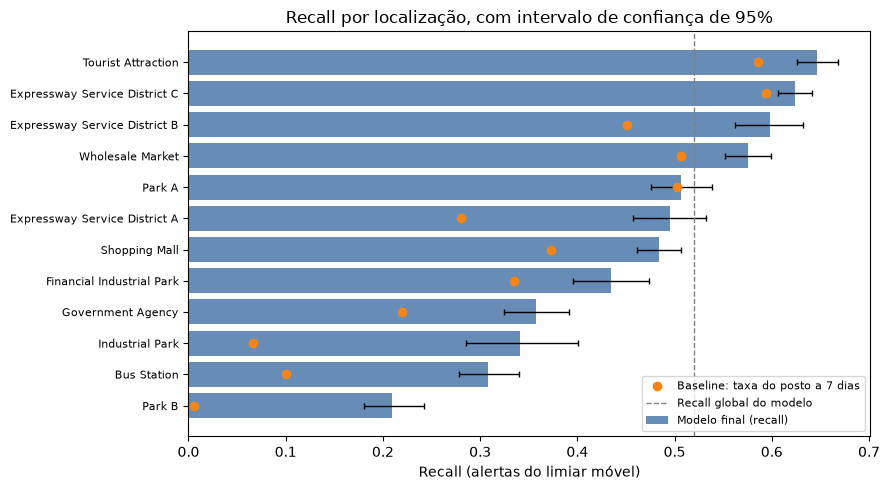

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))
l = loc.iloc[::-1]
y_pos = np.arange(len(l))
rec = l["recall"].astype(float).to_numpy()
ax.barh(y_pos, rec, color="#4C78A8", alpha=0.85, label="Modelo final (recall)")
ax.errorbar(rec, y_pos, xerr=[rec - l["IC95% inf."].astype(float).to_numpy(), l["IC95% sup."].astype(float).to_numpy() - rec],
            fmt="none", ecolor="black", capsize=2, linewidth=1)
ax.scatter(l["recall baseline"].astype(float), y_pos, color="#F58518", zorder=3, label="Baseline: taxa do posto a 7 dias")
ax.axvline(tabela.loc[NOME_RF, "recall"], color="gray", linestyle="--", linewidth=1, label="Recall global do modelo")
ax.set_yticks(y_pos); ax.set_yticklabels([str(i)[:38] for i in l.index], fontsize=8)
ax.set_xlabel("Recall (alertas do limiar móvel)"); ax.set_title("Recall por localização, com intervalo de confiança de 95%")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

**Conclusão.** O modelo ganha à baseline da taxa do posto a 7 dias nos três distritos (+0,070 em Nanhu, +0,083 em Xiuzhou e +0,128 em Tongxiang) e nas 12 localizações com sessões no teste, mas o desempenho varia muito entre grupos. O recall é de 0,597 em Nanhu, 0,566 em Xiuzhou e 0,409 em Tongxiang, e os intervalos de confiança de Tongxiang não se sobrepõem aos dos outros dois. Nas localizações vai de 0,647 (Tourist Attraction) a 0,209 (Park B). A variação acompanha a taxa de falhas: as localizações com prevalência de 23% a 27% têm recall de 0,58 a 0,65, com exceção do Park A (0,51), e as de cerca de 7% têm 0,21 a 0,34. A precisão dos alertas é parecida entre grupos (0,45 a 0,49 nos distritos), o que muda é o número de alertas: com um limiar único, Tongxiang recebe 100 alertas por 1000 sessões e os outros dois distritos cerca de 280 a 300. Explica-se por o modelo assentar no histórico recente de falhas, que é mais raro onde as falhas são menos frequentes. O ganho sobre a baseline é maior onde esta quase não alerta (Industrial Park, Park B e Bus Station, +0,20 a +0,28) e na Expressway Service District A (+0,215) e é mínimo no Park A (+0,005, dentro do intervalo de confiança).

## 4. Desempenho por posto

O conjunto de dados tem 92 postos, dos quais 88 têm sessões no teste. Para as tabelas de ordenação consideram-se só os postos com pelo menos MIN_SESSOES_POSTO (200) sessões no teste: são 86 e cobrem 99,6% das sessões. Os outros 2 entram nas contagens totais, mas os seus recalls não são fiáveis.

A pergunta é se o modelo trata bem todos os postos ou se se limita a alertar nos postos que já falham muito. Mede-se com a correlação entre a prevalência de falhas de cada posto e o seu recall, e com a concentração dos alertas e dos erros em poucos postos.

In [39]:
postos = por_grupo(teste["Charging Post ID"].to_numpy())
grandes = postos[postos["sessões"] >= MIN_SESSOES_POSTO].copy()
for c in grandes.columns:
    grandes[c] = pd.to_numeric(grandes[c], errors="coerce")
print(f"{len(postos)} postos no teste; {len(grandes)} com pelo menos {MIN_SESSOES_POSTO} sessões "
      f"({grandes['sessões'].sum() / len(teste):.1%} das sessões do teste)")

rho_rec, p_rec = spearmanr(grandes["prevalência"], grandes["recall"], nan_policy="omit")
rho_al, p_al = spearmanr(grandes["prevalência"], grandes["% dos alertas"] / grandes["% das sessões"], nan_policy="omit")
print(f"correlação de Spearman entre a prevalência do posto e o recall: {rho_rec:.2f} (p = {p_rec:.3f})")
print(f"correlação de Spearman entre a prevalência do posto e o peso relativo dos alertas: {rho_al:.2f} (p = {p_al:.3f})")

colunas = ["sessões", "prevalência", "alertas/1000", "precisão", "recall", "IC95% inf.", "IC95% sup.", "recall baseline",
           "% dos falsos alertas", "% das falhas não detetadas"]
print("\nPostos com MENOR recall:")
display(grandes.sort_values("recall").head(10)[colunas].round(3))
print("Postos com MAIOR recall:")
display(grandes.sort_values("recall", ascending=False).head(10)[colunas].round(3))

menores = grandes.sort_values("recall").head(10)
razao = menores["precisão"] / menores["prevalência"]
print(f"precisão / prevalência nos 10 postos com menor recall: {razao.min():.1f} a {razao.max():.1f}")

88 postos no teste; 86 com pelo menos 200 sessões (99.6% das sessões do teste)
correlação de Spearman entre a prevalência do posto e o recall: 0.77 (p = 0.000)
correlação de Spearman entre a prevalência do posto e o peso relativo dos alertas: 0.98 (p = 0.000)

Postos com MENOR recall:


,sessões,prevalência,alertas/1000,precisão,recall,IC95% inf.,IC95% sup.,recall baseline,% dos falsos alertas,% das falhas não detetadas
52,1213.0,0.035,16.488,0.200,0.095,0.038,0.221,0.0,0.002,0.006
65,828.0,0.083,41.063,0.206,0.101,0.050,0.195,0.0,0.003,0.009
38,637.0,0.038,17.268,0.273,0.125,0.043,0.310,0.0,0.001,0.003
10,461.0,0.095,60.738,0.214,0.136,0.064,0.267,0.0,0.003,0.006
51,1325.0,0.082,46.038,0.262,0.147,0.092,0.225,0.0,0.005,0.014
56,1411.0,0.086,45.358,0.281,0.149,0.096,0.223,0.0,0.006,0.015
42,384.0,0.052,28.646,0.273,0.150,0.052,0.360,0.0,0.001,0.003
53,1409.0,0.045,26.260,0.270,0.156,0.087,0.264,0.0,0.003,0.008
58,1212.0,0.088,42.079,0.333,0.159,0.102,0.240,0.0,0.004,0.013
50,1144.0,0.093,41.958,0.354,0.160,0.103,0.242,0.0,0.004,0.013


Postos com MAIOR recall:


,sessões,prevalência,alertas/1000,precisão,recall,IC95% inf.,IC95% sup.,recall baseline,% dos falsos alertas,% das falhas não detetadas
89,802.0,0.476,796.758,0.527,0.882,0.846,0.911,0.966,0.036,0.007
32,731.0,0.532,751.026,0.597,0.843,0.804,0.876,0.956,0.027,0.009
4,668.0,0.440,627.246,0.566,0.806,0.757,0.847,0.871,0.022,0.008
83,1816.0,0.395,786.344,0.403,0.801,0.770,0.828,1.000,0.103,0.021
27,1338.0,0.462,540.359,0.682,0.798,0.764,0.828,0.824,0.028,0.018
72,480.0,0.325,429.167,0.578,0.763,0.690,0.823,0.667,0.010,0.005
5,973.0,0.276,297.020,0.689,0.740,0.684,0.789,0.550,0.011,0.010
81,1450.0,0.350,439.310,0.579,0.728,0.687,0.765,0.724,0.032,0.020
2,807.0,0.357,536.555,0.460,0.691,0.635,0.742,0.875,0.028,0.013
78,1278.0,0.338,410.798,0.566,0.688,0.642,0.729,0.632,0.027,0.020


precisão / prevalência nos 10 postos com menor recall: 2.2 a 7.2


metade dos falsos alertas vem de 15 postos (de 88)
metade das falhas não detetadas vem de 27 postos
metade dos alertas vem de 14 postos


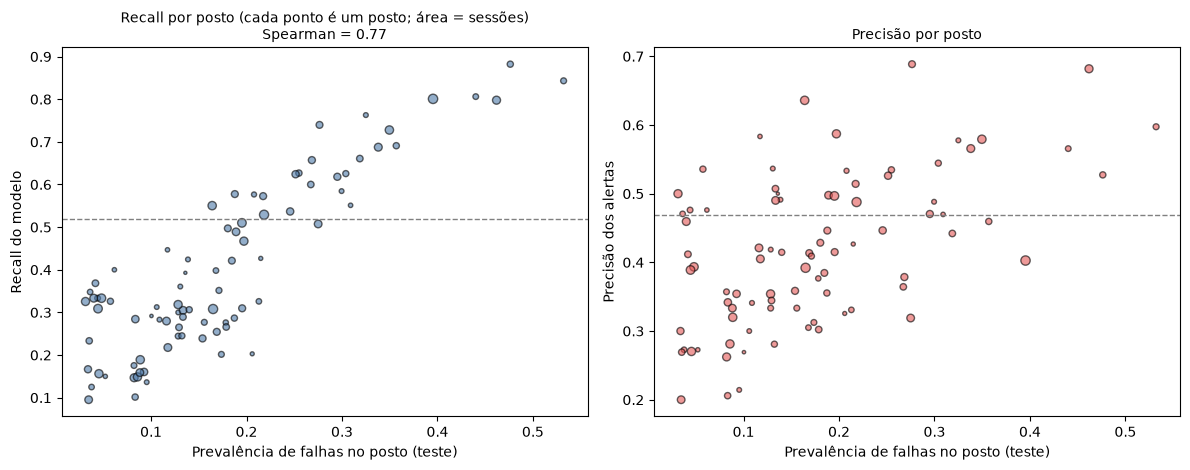

In [40]:
# Concentração: quantos postos explicam metade dos falsos alertas e das falhas não detetadas?
def postos_para(coluna, fracao=0.5):
    s = postos[coluna].astype(float).sort_values(ascending=False).cumsum()
    return int((s < fracao).sum() + 1)

print(f"metade dos falsos alertas vem de {postos_para('% dos falsos alertas')} postos (de {len(postos)})")
print(f"metade das falhas não detetadas vem de {postos_para('% das falhas não detetadas')} postos")
print(f"metade dos alertas vem de {postos_para('% dos alertas')} postos")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8))
ax = eixos[0]
ax.scatter(grandes["prevalência"], grandes["recall"], s=grandes["sessões"] / 40, alpha=0.6, color="#4C78A8", edgecolor="black")
ax.axhline(tabela.loc[NOME_RF, "recall"], color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Prevalência de falhas no posto (teste)"); ax.set_ylabel("Recall do modelo")
ax.set_title(f"Recall por posto (cada ponto é um posto; área = sessões)\nSpearman = {rho_rec:.2f}", fontsize=10)
ax = eixos[1]
ax.scatter(grandes["prevalência"], grandes["precisão"], s=grandes["sessões"] / 40, alpha=0.6, color="#E45756", edgecolor="black")
ax.axhline(tabela.loc[NOME_RF, "precisão"], color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Prevalência de falhas no posto (teste)"); ax.set_ylabel("Precisão dos alertas")
ax.set_title("Precisão por posto", fontsize=10)
plt.tight_layout(); plt.show()

**Conclusão.** O desempenho varia muito entre postos e acompanha a taxa de falhas de cada um (correlação de Spearman de 0,77 entre a prevalência do posto e o recall). Nos 10 postos com menor recall (0,095 a 0,160), a prevalência é baixa (0,035 a 0,095) e o modelo emite apenas 16 a 61 alertas por 1000 sessões; a precisão desses alertas (0,20 a 0,35) é, ainda assim, 2,2 a 7,2 vezes a taxa de falhas do posto, e a baseline da taxa do posto a 7 dias não deteta nenhuma falha neles. Nos 10 postos com maior recall (0,688 a 0,882), a prevalência é de 0,28 a 0,53 e o modelo emite 300 a 800 alertas por 1000 sessões; aqui a baseline deteta igual ou mais falhas em 6 dos 10 postos, porque alerta em quase todas as sessões de um posto avariado. O ganho do modelo vem dos postos com poucas ou médias falhas, onde a taxa do posto não chega. Os alertas e os erros concentram-se: metade dos alertas vem de 14 postos e metade dos falsos alertas de 15, de 88 postos, e metade das falhas não detetadas de 27. Os intervalos de confiança dos postos pequenos são largos, pelo que não se devem tirar conclusões de um posto isolado.

## 5. Análise de erros

Os erros são de dois tipos (secção 8.3 do relatório): **falsos alertas** (sessão normal sinalizada) e **falhas não detetadas** (sessão anómala sem alerta). Para ver se há padrões, comparam-se os dois tipos de erro com os acertos nos mesmos grupos de sessões. A causa de fim (`end_cause`) só existe depois da sessão, por isso serve **apenas para esta análise**, nunca como preditor.

In [41]:
# Matriz de confusão do modelo final (limiar móvel), por 1000 sessões
tp = int(((pred_rf == 1) & (y_t == 1)).sum()); fp = FP_TOTAL; fn = FN_TOTAL
tn = int(((pred_rf == 0) & (y_t == 0)).sum())
conf = pd.DataFrame({"alerta": [tp, fp], "sem alerta": [fn, tn]}, index=["sessão anómala", "sessão normal"])
display(conf)
display((1000 * conf / len(y_t)).round(1).rename_axis("por 1000 sessões"))

,alerta,sem alerta
sessão anómala,7329,6759
sessão normal,8316,57677


,alerta,sem alerta
por 1000 sessões,,
sessão anómala,91.5,84.4
sessão normal,103.8,720.2


### 5.1 Que tipos de falha o modelo apanha e quais deixa passar

Para cada causa de fim, mede-se que fração das falhas teve alerta (o recall dessa causa).

In [42]:
falha_m = y_t == 1
causa = teste.loc[falha_m, "end_cause"].reset_index(drop=True)
alerta_f = pd.Series(pred_rf[falha_m])
score_f = pd.Series(s_t[falha_m])
causas = pd.DataFrame({"falhas": causa.groupby(causa).size()})
causas["% das falhas"] = causas["falhas"] / causas["falhas"].sum()
causas["recall (com alerta)"] = alerta_f.groupby(causa).mean()
causas["score médio"] = score_f.groupby(causa).mean()
causas["IC95% inf."] = [wilson(int(round(r * n)), n)[0] for r, n in zip(causas["recall (com alerta)"], causas["falhas"])]
causas["IC95% sup."] = [wilson(int(round(r * n)), n)[1] for r, n in zip(causas["recall (com alerta)"], causas["falhas"])]
nao_det = (1 - alerta_f).groupby(causa).sum()
causas["% das falhas não detetadas"] = nao_det / nao_det.sum()
causas = causas.sort_values("falhas", ascending=False)
causas.round(3)

,falhas,% das falhas,recall (com alerta),score médio,IC95% inf.,IC95% sup.,% das falhas não detetadas
end_cause,,,,,,,
Other faults of the charging pile,3197,0.227,0.505,0.405,0.487,0.522,0.234
Vehicle communications failure,2316,0.164,0.550,0.376,0.530,0.570,0.154
DC Output Fault,2226,0.158,0.475,0.316,0.455,0.496,0.173
Vehicle charging faults,1661,0.118,0.693,0.438,0.670,0.715,0.075
BMS failure,1586,0.113,0.438,0.288,0.413,0.462,0.132
Faulty charging connection,1525,0.108,0.490,0.320,0.465,0.516,0.115
Failure of non-system control loop components and assemblies,818,0.058,0.364,0.288,0.332,0.398,0.077
DC switching device failure,467,0.033,0.677,0.507,0.633,0.717,0.022
Power conversion unit failure,259,0.018,0.606,0.408,0.546,0.664,0.015


**Conclusão.** O recall varia entre causas de fim, de 0,364 a 0,693 nas que têm mais de 250 falhas (o global é 0,520), e os intervalos de confiança confirmam as diferenças. As mais detetadas são Vehicle charging faults (0,693), DC switching device failure (0,677) e Power conversion unit failure (0,606); as menos detetadas, Failure of non-system control loop components (0,364), BMS failure (0,438) e DC Output Fault (0,475). A variação não separa as falhas do equipamento das do veículo: uma falha de veículo (Vehicle charging faults) é a mais detetada e outra (BMS failure) está entre as menos detetadas, e o mesmo acontece no equipamento. As falhas não detetadas repartem-se por várias causas, sem nenhuma dominante (Other faults of the charging pile, cerca de 23%; DC Output Fault, 17%; Vehicle communications failure, 15%; BMS failure, 13%), pelo que a dificuldade não está num tipo de falha em particular. As causas com menos de 20 falhas têm intervalos de confiança demasiado largos para qualquer conclusão. A causa de fim só se conhece depois da sessão, por isso esta análise é só diagnóstico.

### 5.2 O estado do posto e do utilizador no início da sessão

O modelo vive do histórico recente de falhas (secção 10.4 do relatório). A pergunta é então: **onde é que esse histórico não chega?** Compara-se o desempenho consoante o posto tivesse ou não falhas recentes, e consoante o utilizador tivesse ou não histórico.

In [43]:
falhas_1d = pd.cut(teste["post_previous_abnormal_1D"], [-0.5, 0.5, 2.5, 5.5, np.inf],
                   labels=["0 falhas", "1–2 falhas", "3–5 falhas", "6 ou mais falhas"])
est_posto = por_grupo(falhas_1d.astype(str).to_numpy(), ordem=["0 falhas", "1–2 falhas", "3–5 falhas", "6 ou mais falhas"])
print("Falhas no posto nas últimas 24 horas (antes do início da sessão):")
display(est_posto.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

ultima_rot = np.where(teste["post_last_completed_abnormal"].to_numpy() == 1, "última sessão do posto anómala", "última sessão do posto normal")
ultima_tab = por_grupo(ultima_rot)
print("Resultado da última sessão concluída no posto:")
display(ultima_tab.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

sem_dia = np.where(teste["post_previous_sessions_1D"].to_numpy() == 0, "posto sem sessões nas últimas 24 h", "posto com sessões nas últimas 24 h")
atividade_tab = por_grupo(sem_dia)
print("Atividade do posto no último dia:")
display(atividade_tab.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

utilizador = np.select([teste["user_no_previous_completed_session"].to_numpy() == 1,
                        teste["user_previous_abnormal_180D"].to_numpy() > 0],
                       ["utilizador sem histórico", "utilizador com falhas nos últimos 180 dias"],
                       default="utilizador com histórico, sem falhas nos últimos 180 dias")
util_tab = por_grupo(utilizador)
print("Histórico do utilizador:")
display(util_tab.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

Falhas no posto nas últimas 24 horas (antes do início da sessão):


,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
0 falhas,23998.0,0.300,2026.0,0.084,0.043,28.044,0.363,0.120,0.095,0.052,0.264,0.025
1–2 falhas,30854.0,0.385,4389.0,0.142,0.255,129.513,0.378,0.344,0.200,0.299,0.426,0.145
3–5 falhas,15959.0,0.199,3496.0,0.219,0.298,291.873,0.415,0.553,0.426,0.328,0.231,0.127
6 ou mais falhas,9270.0,0.116,4177.0,0.451,0.404,681.553,0.576,0.871,0.820,0.322,0.079,0.051


Resultado da última sessão concluída no posto:


,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
última sessão do posto anómala,14091.0,0.176,6001.0,0.426,0.632,701.795,0.542,0.892,0.612,0.545,0.096,0.280
última sessão do posto normal,65990.0,0.824,8087.0,0.123,0.368,87.225,0.343,0.244,0.286,0.455,0.904,-0.042


Atividade do posto no último dia:


,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
posto com sessões nas últimas 24 h,79940.0,0.998,14052.0,0.176,0.997,195.134,0.468,0.520,0.425,0.997,0.998,0.095
posto sem sessões nas últimas 24 h,141.0,0.002,36.0,0.255,0.003,326.241,0.457,0.583,0.389,0.003,0.002,0.194


Histórico do utilizador:


,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
utilizador com falhas nos últimos 180 dias,51984.0,0.649,10343.0,0.199,0.820,246.749,0.485,0.601,0.424,0.795,0.611,0.177
"utilizador com histórico, sem falhas nos últimos 180 dias",17647.0,0.220,1903.0,0.108,0.061,53.947,0.460,0.230,0.419,0.062,0.217,-0.189
utilizador sem histórico,10450.0,0.130,1842.0,0.176,0.119,178.565,0.362,0.367,0.437,0.143,0.173,-0.070


**Conclusão.** As falhas não detetadas concentram-se nas sessões em que o posto não tinha falhado há pouco, ou seja, na primeira falha de uma série. Quando a última sessão do posto foi normal, ocorrem 57% das falhas, o recall é de 0,244 e vêm daí 90,4% das falhas não detetadas; quando foi anómala, o recall é de 0,892. Pelas falhas nas últimas 24 horas, o recall sobe de 0,120 (nenhuma falha) para 0,344 (1–2), 0,553 (3–5) e 0,871 (6 ou mais), e os dois primeiros grupos concentram 69% das falhas não detetadas com 68,5% das sessões. Os alertas concentram-se nos postos já problemáticos (682 por 1000 sessões com 6 ou mais falhas no último dia, contra 28 sem falhas). O ganho sobre a baseline está nas situações intermédias (+0,145 com 1–2 falhas e +0,127 com 3–5) e é pequeno nos postos muito avariados (+0,051). O histórico do utilizador também condiciona o resultado: com falhas nos últimos 180 dias, o recall é de 0,601; sem falhas nos últimos 180 dias, de 0,230, e sem histórico, de 0,367, e nos dois últimos grupos o modelo fica abaixo da baseline da taxa do posto (0,419 e 0,437). O modelo reconhece os postos que já estão a falhar, mas não antecipa o início de uma série de falhas e trata como baixo risco os utilizadores sem falhas recentes. O grupo dos postos sem sessões nas últimas 24 horas tem apenas 141 sessões e não permite conclusões.

### 5.3 Hora do dia e dia da semana

A hora e o dia da semana não entram no modelo com peso relevante (secção 10.4). Convém verificar que o desempenho também não varia muito com eles, ou seja, que o modelo não é, por exemplo, mais fraco à noite.

In [44]:
hora = pd.cut(teste["hour"], [-1, 5, 11, 17, 23], labels=["0–5 h", "6–11 h", "12–17 h", "18–23 h"]).astype(str)
hora_tab = por_grupo(hora.to_numpy(), ordem=["0–5 h", "6–11 h", "12–17 h", "18–23 h"])
display(hora_tab.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

dias = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]
dow = teste["dow"].map(dict(enumerate(dias))).to_numpy()
dia_tab = por_grupo(dow, ordem=dias)
display(dia_tab.drop(columns=["IC95% inf.", "IC95% sup."]).round(3))

,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
0–5 h,7474.0,0.093,1604.0,0.215,0.129,270.538,0.482,0.607,0.495,0.126,0.093,0.112
6–11 h,17692.0,0.221,2968.0,0.168,0.204,180.647,0.451,0.486,0.402,0.211,0.226,0.084
12–17 h,30465.0,0.380,5262.0,0.173,0.372,191.006,0.465,0.514,0.424,0.374,0.378,0.090
18–23 h,24450.0,0.305,4254.0,0.174,0.295,188.466,0.479,0.519,0.415,0.289,0.303,0.103


,sessões,% das sessões,falhas,prevalência,% dos alertas,alertas/1000,precisão,recall,recall baseline,% dos falsos alertas,% das falhas não detetadas,dif. recall (modelo − baseline)
segunda,11463.0,0.143,1951.0,0.170,0.144,195.935,0.455,0.523,0.424,0.147,0.138,0.099
terça,11333.0,0.142,2043.0,0.180,0.144,198.447,0.487,0.536,0.436,0.139,0.140,0.100
quarta,11202.0,0.140,2113.0,0.189,0.149,208.177,0.503,0.555,0.453,0.139,0.139,0.102
quinta,10951.0,0.137,1861.0,0.170,0.136,194.777,0.438,0.502,0.412,0.144,0.137,0.091
sexta,12484.0,0.156,2170.0,0.174,0.150,188.401,0.458,0.497,0.417,0.153,0.162,0.080
sábado,11566.0,0.144,2064.0,0.178,0.144,194.276,0.477,0.519,0.427,0.141,0.147,0.092
domingo,11082.0,0.138,1886.0,0.170,0.133,188.233,0.458,0.506,0.402,0.136,0.138,0.104


**Conclusão.** O desempenho varia pouco com a hora do dia e com o dia da semana, e o modelo ganha à baseline em todas as faixas (+0,084 a +0,112) e em todos os dias (+0,080 a +0,104). O recall é de 0,486 a 0,519 entre as 6 e as 23 h e sobe para 0,607 na madrugada (0 a 5 h), faixa com prevalência mais alta (0,215 contra 0,168 a 0,174) e mais alertas (271 por 1000 sessões, contra 181 a 191). Por dia da semana, vai de 0,497 (sexta) a 0,555 (quarta), uma diferença próxima do intervalo de confiança, e o fim de semana não é pior. As falhas não detetadas repartem-se em proporção às sessões em todas as faixas, sem nenhuma a concentrar os erros. Como a hora e o dia da semana não entram no modelo com peso relevante (secção 10.4), a ligeira diferença da madrugada vem das variáveis de histórico e da prevalência, e não da hora.

### 5.4 Quem são os acertos e os erros: perfil de cada tipo de sessão

Compara-se o valor médio de variáveis-chave nas quatro categorias de sessões: acertos nas falhas (**alerta e falha**), falhas não detetadas (**sem alerta e falha**), falsos alertas (**alerta e normal**) e acertos nas sessões normais (**sem alerta e normal**).

In [45]:
tipo = np.select([(pred_rf == 1) & (y_t == 1), (pred_rf == 0) & (y_t == 1), (pred_rf == 1) & (y_t == 0)],
                ["alerta e falha", "sem alerta e falha", "alerta e normal"], default="sem alerta e normal")
variaveis = {"score": "score", "post_previous_abnormal_rate_1D": "taxa de falhas do posto, 1 dia",
             "post_previous_abnormal_rate_7D": "taxa de falhas do posto, 7 dias",
             "post_previous_abnormal_1D": "falhas no posto, 1 dia",
             "post_previous_sessions_1D": "sessões no posto, 1 dia",
             "post_last_completed_abnormal": "última sessão do posto anómala",
             "user_previous_abnormal_rate_30D": "taxa de falhas do utilizador, 30 dias",
             "user_no_previous_completed_session": "utilizador sem histórico"}
ordem_tipo = ["alerta e falha", "sem alerta e falha", "alerta e normal", "sem alerta e normal"]
perfil = teste.assign(tipo=tipo).groupby("tipo")[list(variaveis)].mean().loc[ordem_tipo].rename(columns=variaveis).T
cont = pd.Series(tipo).value_counts().reindex(ordem_tipo)
display(cont.rename("número de sessões").to_frame().T)
perfil.round(3)

,alerta e falha,sem alerta e falha,alerta e normal,sem alerta e normal
número de sessões,7329,6759,8316,57677


tipo,alerta e falha,sem alerta e falha,alerta e normal,sem alerta e normal
score,0.561,0.151,0.398,0.103
"taxa de falhas do posto, 1 dia",0.402,0.173,0.293,0.141
"taxa de falhas do posto, 7 dias",0.354,0.183,0.289,0.135
"falhas no posto, 1 dia",9.079,2.123,5.068,1.513
"sessões no posto, 1 dia",17.065,12.641,14.525,12.681
última sessão do posto anómala,0.731,0.096,0.545,0.062
"taxa de falhas do utilizador, 30 dias",0.327,0.191,0.288,0.157
utilizador sem histórico,0.092,0.173,0.143,0.129


**Conclusão.** As falhas não detetadas parecem-se com as sessões normais sem alerta e não com as falhas detetadas: o score médio é de 0,151 (contra 0,103 e 0,561), só 9,6% têm a última sessão do posto anómala (contra 6,2% e 73,1%) e o posto tinha em média 2,1 falhas no último dia (contra 1,5 e 9,1). São falhas em postos que pareciam saudáveis, ou seja, imprevisíveis com o histórico disponível, e os utilizadores sem histórico estão sobrerrepresentados (17,3%, contra 9,2% nas falhas detetadas). Os falsos alertas, pelo contrário, vêm de contextos de risco: o score médio é de 0,398, 54,5% têm a última sessão do posto anómala, o posto tinha em média 5,1 falhas no último dia (1,5 nas normais sem alerta) e a taxa de falhas do utilizador a 30 dias (0,288) está mais próxima da das falhas detetadas (0,327) do que da das sessões normais (0,157). O posto estava com problemas, mas a sessão correu bem. O modelo reconhece assim os contextos de risco mas não distingue, dentro deles, as sessões que vão falhar das que não vão, o que limita a precisão dos alertas.

## 6. Valor operacional por decis de risco

Ordenam-se as sessões do teste por score e dividem-se em 10 grupos iguais (decil 10 = 10% com maior risco). A tabela mostra que parte das falhas cada decil concentra e quantas vezes mais falhas tem do que a média (*lift*). Serve para discutir a utilidade operacional: se a equipa só puder tratar uma fração dos alertas, onde estão as falhas.

In [46]:
ordem_score = pd.Series(s_t).rank(method="first")
decil = pd.qcut(ordem_score, 10, labels=range(1, 11)).astype(int).to_numpy()
linhas = {}
total_falhas = y_t.sum()
for d in range(10, 0, -1):
    m = decil == d
    linhas[f"decil {d}"] = {"sessões": int(m.sum()), "score mínimo": s_t[m].min(), "prevalência": y_t[m].mean(),
                            "lift": y_t[m].mean() / y_t.mean(), "% das falhas": y_t[m].sum() / total_falhas}
dec = pd.DataFrame(linhas).T
dec["% acumulada das falhas"] = dec["% das falhas"].cumsum()
dec.round(3)

,sessões,score mínimo,prevalência,lift,% das falhas,% acumulada das falhas
decil 10,8008.0,0.412,0.620,3.524,0.352,0.352
decil 9,8008.0,0.257,0.313,1.778,0.178,0.530
decil 8,8008.0,0.192,0.219,1.244,0.124,0.655
decil 7,8008.0,0.153,0.160,0.911,0.091,0.746
decil 6,8008.0,0.125,0.124,0.705,0.070,0.816
decil 5,8008.0,0.099,0.110,0.625,0.062,0.879
decil 4,8008.0,0.074,0.090,0.512,0.051,0.930
decil 3,8008.0,0.050,0.066,0.373,0.037,0.967
decil 2,8008.0,0.030,0.034,0.196,0.020,0.987
decil 1,8009.0,0.001,0.023,0.132,0.013,1.000


**Conclusão.** As falhas concentram-se nos decis de maior risco do score. O decil 10 tem 62% de falhas (3,5 vezes a média) e reúne 35,2% de todas as falhas; os dois decis mais altos (20% das sessões, o orçamento de 200 alertas por 1000) reúnem 53,0%, o que coincide com o recall do orçamento exato (0,530), e os três mais altos reúnem 65,5%. Os três decis mais baixos reúnem só 3,3% das falhas, com uma prevalência de 2,3% a 6,6%. Isto dá três pontos de funcionamento para uma equipa com capacidade limitada: 100 alertas por 1000 sessões detetam 35% das falhas com precisão de 0,62; 200 detetam 53% com 0,47; 300 detetam 65,5% com 0,38. A partir do decil 7 o lift fica abaixo de 1, ou seja, essas sessões têm menos falhas do que a média. Os decis são calculados com os scores de todo o trimestre de teste, por isso, tal como o orçamento exato, são uma referência e não um procedimento operacional: em operação, o corte seria feito pelo limiar móvel.

## 7. Ficheiros guardados para o relatório

In [47]:
saida = {"task5_metricas_teste.csv": tabela,
         "task5_desempenho_por_distrito.csv": dist,
         "task5_desempenho_por_localizacao.csv": loc,
         "task5_desempenho_por_posto.csv": postos,
         "task5_falhas_por_causa.csv": causas,
         "task5_estado_posto_falhas_24h.csv": est_posto,
         "task5_estado_posto_ultima_sessao.csv": ultima_tab,
         "task5_historico_utilizador.csv": util_tab,
         "task5_perfil_acertos_erros.csv": perfil,
         "task5_desempenho_por_hora.csv": hora_tab,
         "task5_desempenho_por_dia.csv": dia_tab,
         "task5_decis_de_risco.csv": dec}
for nome, t in saida.items():
    t.to_csv(PASTA / nome, encoding="utf-8")
    print(f"{nome:<42} {len(t):>4} linhas")

task5_metricas_teste.csv                      8 linhas
task5_desempenho_por_distrito.csv             3 linhas
task5_desempenho_por_localizacao.csv         12 linhas
task5_desempenho_por_posto.csv               88 linhas
task5_falhas_por_causa.csv                   12 linhas
task5_estado_posto_falhas_24h.csv             4 linhas
task5_estado_posto_ultima_sessao.csv          2 linhas
task5_historico_utilizador.csv                3 linhas
task5_perfil_acertos_erros.csv                8 linhas
task5_desempenho_por_hora.csv                 4 linhas
task5_desempenho_por_dia.csv                  7 linhas
task5_decis_de_risco.csv                     10 linhas


In [48]:
from pathlib import Path
for f in sorted(Path("Resultados").iterdir()):
    print(f"{f.name:<55} {f.stat().st_size / 1e6:8.2f} MB")

pesquisa_boosting_amostra1.csv                              0.02 MB
pesquisa_logistica_amostra1.csv                             0.01 MB
pesquisa_random_forest_amostra1.csv                         0.01 MB
task4_aquecimento_boosting.csv.gz                           0.29 MB
task4_aquecimento_logistica.csv.gz                          0.29 MB
task4_aquecimento_random_forest.csv.gz                      0.29 MB
task4_calibracao.png                                        0.11 MB
task4_importancia_grupos.png                                0.06 MB
task4_limiar.json                                           0.00 MB
task4_modelos_escolhidos.json                               0.00 MB
task4_oof_validacao_boosting.csv.gz                         3.85 MB
task4_oof_validacao_logistica.csv.gz                        3.87 MB
task4_oof_validacao_random_forest.csv.gz                    3.88 MB
task4_teste_previsoes.csv.gz                                1.11 MB
task5_carga_semanal.csv                         

## 8. Seleção do modelo final e tabela concisa

O modelo final foi escolhido na Task 4 (secções 4 a 6 do caderno da Task 4), só com resultados de treino e validação, antes de abrir o teste. Esta secção não escolhe nada de novo: reúne os resultados que fundamentam a escolha e, em bloco separado, o resultado do teste do modelo final e das baselines (Tabela 55).

Os valores de validação são recalculados a partir das previsões guardadas pela Task 4 (`task4_oof_validacao_*.csv.gz`), em que cada fold é previsto por um modelo treinado só com dados anteriores. Não se treina nenhum modelo. As baselines são colunas do conjunto de dados e também não precisam de treino.

### 8.1 Desempenho na validação: candidatos e baselines

In [49]:
import otimizacao as ot

CANDIDATOS = {"logistica": "Regressão logística (inicial)",
              "boosting": "Boosting (otimizado)",
              "random_forest": "Random Forest (inicial): modelo final"}


def resumo_folds(por_fold):
    """Média, desvio-padrão e pior fold do recall com 200 alertas; médias das restantes métricas."""
    r = pd.DataFrame(por_fold).T.astype(float)
    return {"recall@200 (média)": r["recall"].mean(), "desvio": r["recall"].std(ddof=1),
            "pior fold": r["recall"].min(), "precisão": r["precisao"].mean(),
            "PR-AUC norm.": r["pr_auc_norm"].mean(), "ROC-AUC": r["roc_auc"].mean(),
            "corretos/1000": r["alertas_corretos_1000"].mean(),
            "falsos/1000": r["falsos_alertas_1000"].mean(),
            "falhados/1000": r["falhadas_1000"].mean()}


linhas_val, recall_folds = {}, {}

# candidatos: previsões de validação guardadas pela Task 4 (versões escolhidas)
for chave, nome in CANDIDATOS.items():
    oof = pd.read_csv(PASTA / f"task4_oof_validacao_{chave}.csv.gz")
    por_fold, sc = {}, {}
    for f, g in oof.groupby("fold", sort=True):
        y, s = g["y"].to_numpy(), g["score"].to_numpy()
        pred = av.alertas_por_orcamento(s, X_ALERTAS)
        por_fold[f] = av.avaliar(y, s, pred=pred)
        sc[f] = (y, s, pred)
    linhas_val[nome] = {**resumo_folds(por_fold), **ot.metricas_probabilisticas(sc)}
    recall_folds[nome] = {f: v["recall"] for f, v in por_fold.items()}

# baselines: colunas do conjunto de dados, nos mesmos folds, sem treino
for col, nome in [(col7, "Baseline: taxa do posto a 7 dias"),
                  ("post_last_completed_abnormal", "Baseline: última sessão do posto anómala")]:
    por_fold = {}
    y_dev, s_dev = dev_final["is_Abnormal"].to_numpy(), dev_final[col].to_numpy(dtype=float)
    for f, _, va in av.folds_temporais(dev_final["Start Time"]):
        por_fold[f] = av.avaliar(y_dev[va], s_dev[va], pred=av.alertas_por_orcamento(s_dev[va], X_ALERTAS))
    linhas_val[nome] = resumo_folds(por_fold)
    recall_folds[nome] = {f: v["recall"] for f, v in por_fold.items()}

tab_val = pd.DataFrame(linhas_val).T
display(tab_val.round(4))
pd.DataFrame(recall_folds).round(4).rename_axis("recall@200 por fold")

,recall@200 (média),desvio,pior fold,precisão,PR-AUC norm.,ROC-AUC,corretos/1000,falsos/1000,falhados/1000,Brier,log-loss,ECE
Regressão logística (inicial),0.5788,0.0136,0.5664,0.5208,0.5202,0.8298,104.1632,95.8342,75.8934,0.1044,0.3453,0.0138
Boosting (otimizado),0.5877,0.0140,0.5744,0.5288,0.5466,0.8358,105.7499,94.2475,74.3067,0.1017,0.3375,0.0097
Random Forest (inicial): modelo final,0.5877,0.0138,0.5759,0.5288,0.5467,0.8344,105.7682,94.2291,74.2883,0.1016,0.3368,0.0057
Baseline: taxa do posto a 7 dias,0.4993,0.0236,0.4703,0.4509,0.4036,0.7723,90.1706,109.8267,89.8859,NaN,NaN,NaN
Baseline: última sessão do posto anómala,0.5114,0.0199,0.4821,0.4614,0.2006,0.6980,92.2810,107.7164,87.7756,NaN,NaN,NaN


,Regressão logística (inicial),Boosting (otimizado),Random Forest (inicial): modelo final,Baseline: taxa do posto a 7 dias,Baseline: última sessão do posto anómala
recall@200 por fold,,,,,
F1,0.5886,0.5969,0.5974,0.4920,0.5196
F2,0.5678,0.5771,0.5759,0.4703,0.4821
F3,0.5924,0.6023,0.6016,0.5250,0.5261
F4,0.5664,0.5744,0.5759,0.5097,0.5179


In [50]:
esperado_51 = {   # recall, desvio, PR-AUC norm., ROC-AUC, Brier, log-loss, ECE
    "Regressão logística (inicial)":        (0.5788, 0.0136, 0.5202, 0.8298, 0.1044, 0.3453, 0.0138),
    "Boosting (otimizado)":                 (0.5877, 0.0140, 0.5466, 0.8358, 0.1017, 0.3375, 0.0097),
    "Random Forest (inicial): modelo final": (0.5877, 0.0138, 0.5467, 0.8344, 0.1016, 0.3368, 0.0057)}
cols_51 = ["recall@200 (média)", "desvio", "PR-AUC norm.", "ROC-AUC", "Brier", "log-loss", "ECE"]
ok = True
for nome, valores in esperado_51.items():
    for c, v in zip(cols_51, valores):
        if abs(tab_val.loc[nome, c] - v) > 0.0006:
            ok = False
            print(f"DIFERENTE: {nome} | {c}: obtido {tab_val.loc[nome, c]:.4f}, Tabela 51 {v}")
print("Confere com a Tabela 51." if ok else "ATENÇÃO: há diferenças em relação à Tabela 51 (ver acima).")

Confere com a Tabela 51.


### 8.2 Critérios da escolha: comparação fold a fold, estabilidade e custo

A regra da secção 8.9 do relatório, fixada antes da otimização, prefere um modelo a outro se tiver maior recall médio, for melhor em pelo menos 3 dos 4 folds e tiver pior fold não inferior; caso contrário há empate, resolvido pelo menor desvio-padrão entre folds, pela maior PR-AUC normalizada e pela simplicidade. O custo é o tempo de treino e previsão nos 4 folds, medido na pesquisa da Task 4 (a Random Forest com 100 árvores; o modelo final tem 200).

In [51]:
RF_NOME = "Random Forest (inicial): modelo final"
rec = pd.DataFrame(recall_folds)

# Random Forest contra cada alternativa, fold a fold (regra da secção 8.9)
linhas_cmp = {}
for outro in [c for c in rec.columns if c != RF_NOME]:
    d = rec[RF_NOME] - rec[outro]
    linhas_cmp[outro] = {"diferença média de recall (RF − outro)": d.mean(),
                         "folds em que a RF é melhor": int((d > 0).sum()),
                         "pior fold RF": rec[RF_NOME].min(), "pior fold outro": rec[outro].min(),
                         "falhas detetadas a mais por 1000 (RF − outro)":
                             tab_val.loc[RF_NOME, "corretos/1000"] - tab_val.loc[outro, "corretos/1000"]}
cmp_rf = pd.DataFrame(linhas_cmp).T
display(cmp_rf.round(4))

# custo: tempo nos 4 folds da pesquisa, para a versão escolhida de cada modelo
with open(PASTA / "task4_modelos_escolhidos.json", encoding="utf-8") as fh:
    escolhas = json.load(fh)
tempos = {}
for chave, nome in CANDIDATOS.items():
    p = pd.read_csv(PASTA / f"pesquisa_{chave}_amostra1.csv")
    hp = escolhas["hiperparametros_escolhidos"][chave]
    linha = p[p["hp"] == json.dumps(hp, sort_keys=True, default=str)]
    assert len(linha) == 1, f"configuração escolhida de {chave} não encontrada na pesquisa"
    tempos[nome] = float(linha["tempo_s"].iloc[0])

criterios = tab_val.loc[list(CANDIDATOS.values()),
                        ["recall@200 (média)", "desvio", "pior fold", "PR-AUC norm.", "ROC-AUC", "Brier", "ECE"]].copy()
criterios["tempo nos 4 folds (s)"] = pd.Series(tempos)
criterios.round(4)

,diferença média de recall (RF − outro),folds em que a RF é melhor,pior fold RF,pior fold outro,falhas detetadas a mais por 1000 (RF − outro)
Regressão logística (inicial),0.0089,4.0,0.5759,0.5664,1.6051
Boosting (otimizado),0.0000,2.0,0.5759,0.5744,0.0183
Baseline: taxa do posto a 7 dias,0.0884,4.0,0.5759,0.4703,15.5976
Baseline: última sessão do posto anómala,0.0763,4.0,0.5759,0.4821,13.4873


,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,Brier,ECE,tempo nos 4 folds (s)
Regressão logística (inicial),0.5788,0.0136,0.5664,0.5202,0.8298,0.1044,0.0138,6.1865
Boosting (otimizado),0.5877,0.0140,0.5744,0.5466,0.8358,0.1017,0.0097,28.6916
Random Forest (inicial): modelo final,0.5877,0.0138,0.5759,0.5467,0.8344,0.1016,0.0057,204.5700


### 8.3 Tabela concisa: candidatos, baselines e modelo final

Dois blocos, para comparar sempre no mesmo período: **validação** (média dos 4 folds; recall com 200 alertas por 1000 sessões, orçamento exato), com os três candidatos e as duas baselines; e **teste** (avaliado uma única vez na Task 4; valores da Tabela 55 e da secção 2 deste caderno), com o modelo final, o limiar oficial (limiar móvel de 7 dias) e as baselines com o mesmo procedimento de limiar.

In [52]:
COLS_VAL = ["recall@200 (média)", "desvio", "pior fold", "precisão", "PR-AUC norm.",
            "corretos/1000", "falsos/1000", "falhados/1000"]
bloco_val = tab_val[COLS_VAL]
print("Validação (média dos 4 folds):")
display(bloco_val.round(3))

COLS_TESTE = ["alertas/1000", "precisão", "recall", "F1", "balanced accuracy", "MCC",
              "PR-AUC", "PR-AUC norm.", "corretos/1000", "falsos/1000", "falhados/1000"]
bloco_teste = tabela.loc[[NOME_RF, NOME_BASE, "Última sessão anómala: regra pura"], COLS_TESTE]
print("Teste (avaliado uma única vez):")
display(bloco_teste.round(3))

for nome, t in {"task5_validacao_candidatos_baselines.csv": tab_val,
                "task5_criterios_selecao.csv": criterios.join(cmp_rf, how="outer"),
                "task5_tabela_concisa_validacao.csv": bloco_val,
                "task5_tabela_concisa_teste.csv": bloco_teste}.items():
    t.to_csv(PASTA / nome, encoding="utf-8")
    print(f"guardado: {nome}")

Validação (média dos 4 folds):


,recall@200 (média),desvio,pior fold,precisão,PR-AUC norm.,corretos/1000,falsos/1000,falhados/1000
Regressão logística (inicial),0.579,0.014,0.566,0.521,0.520,104.163,95.834,75.893
Boosting (otimizado),0.588,0.014,0.574,0.529,0.547,105.750,94.247,74.307
Random Forest (inicial): modelo final,0.588,0.014,0.576,0.529,0.547,105.768,94.229,74.288
Baseline: taxa do posto a 7 dias,0.499,0.024,0.470,0.451,0.404,90.171,109.827,89.886
Baseline: última sessão do posto anómala,0.511,0.020,0.482,0.461,0.201,92.281,107.716,87.776


Teste (avaliado uma única vez):


,alertas/1000,precisão,recall,F1,balanced accuracy,MCC,PR-AUC,PR-AUC norm.,corretos/1000,falsos/1000,falhados/1000
RF: limiar móvel de 7 dias (principal),195.365,0.468,0.520,0.493,0.697,0.379,0.536,0.437,91.520,103.845,84.402
Taxa do posto 7 dias: limiar móvel,192.530,0.388,0.425,0.406,0.641,0.272,0.381,0.249,74.749,117.781,101.173
Última sessão anómala: regra pura,175.959,0.426,0.426,0.426,0.652,0.303,0.282,0.129,74.937,101.023,100.985


guardado: task5_validacao_candidatos_baselines.csv
guardado: task5_criterios_selecao.csv
guardado: task5_tabela_concisa_validacao.csv
guardado: task5_tabela_concisa_teste.csv


## 9. Ficha do modelo final

Tudo o que define o modelo final, lido dos ficheiros fixados antes do teste (`task4_modelos_escolhidos.json` e `task4_limiar.json`) e do módulo de pré-processamento (`ablacao.py`). O pipeline é construído com a mesma função usada no caderno da Task 4 (secção 11), mas não é treinado aqui.

In [53]:
MODELO_FINAL = escolhas["modelo_probabilistico_mais_forte"]            # "random_forest"
hp_final = escolhas["hiperparametros_escolhidos"][MODELO_FINAL]
GRUPOS_FINAIS = ab.CONFIGURACOES["4 + histórico do utilizador"]
cols_final, pipe_final = ab.criar_pipeline(MODELO_FINAL, GRUPOS_FINAIS, None, **hp_final)   # None = sem informação espacial
print(pipe_final.named_steps["modelo"])

# Período de treino do modelo final
print(f"\nTreino do modelo final: {len(dev_final):,} sessões, de {dev_final['Start Time'].min():%Y-%m-%d} "
      f"a {dev_final['Start Time'].max():%Y-%m-%d}, prevalência {dev_final['is_Abnormal'].mean():.1%}")

# 1) Variáveis por grupo
ficha_var = pd.DataFrame([(g, c) for g in GRUPOS_FINAIS for c in ab.GRUPOS[g]], columns=["grupo", "variável"])
print(f"\n{len(cols_final)} variáveis de entrada:")
display(ficha_var.groupby("grupo", sort=False).size().rename("n.º de variáveis").to_frame().T)

# 2) Pré-processamento: cada bloco do ColumnTransformer, os seus passos e as colunas a que se aplica
DESC = {"SimpleImputer": "imputação pela mediana do treino", "LimiteSuperior": "limite no percentil 99 do treino",
        "FunctionTransformer": "log1p", "StandardScaler": "escalonamento"}
linhas_pre = []
for nome, trans, cols in pipe_final.named_steps["pre"].transformers:
    passos = "sem transformação" if trans == "passthrough" else \
             " → ".join(DESC.get(type(p).__name__, type(p).__name__) for _, p in trans.steps)
    linhas_pre.append({"bloco": nome, "passos": passos, "n.º": len(cols), "variáveis": ", ".join(cols)})
ficha_pre = pd.DataFrame(linhas_pre)
with pd.option_context("display.max_colwidth", None):
    display(ficha_pre)

RandomForestClassifier(max_features=0.5, min_samples_leaf=50, n_estimators=200,
                       n_jobs=-1, random_state=0)

Treino do modelo final: 360,996 sessões, de 2019-12-31 a 2021-09-30, prevalência 18.8%

30 variáveis de entrada:


grupo,tempo,meteorologia,tarifa,historico_posto,historico_utilizador
n.º de variáveis,2,3,1,12,12


,bloco,passos,n.º,variáveis
0,imp_log,imputação pela mediana do treino → log1p,4,"post_hours_since_previous_completed_session, post_hours_since_previous_completed_abnormal, user_days_since_previous_completed_session, user_days_since_previous_completed_abnormal"
1,log,log1p,8,"Precipitation(mm), post_previous_abnormal_1D, post_previous_abnormal_7D, post_previous_abnormal_30D, user_previous_sessions_30D, user_previous_abnormal_30D, user_previous_sessions_180D, user_previous_abnormal_180D"
2,cap,limite no percentil 99 do treino,1,user_active_sessions_at_start
3,resto,sem transformação,13,"hour, dow, Temperature(℃), Relative Humidity(%), electricity_price, post_previous_sessions_1D, post_previous_abnormal_rate_1D, post_previous_sessions_7D, post_previous_abnormal_rate_7D, post_previous_sessions_30D, post_previous_abnormal_rate_30D, user_previous_abnormal_rate_30D, user_previous_abnormal_rate_180D"
4,bin,sem transformação,4,"post_last_completed_abnormal, user_no_previous_completed_session, user_no_previous_completed_abnormal, user_last_completed_abnormal"


In [54]:
# 3) Hiperparâmetros: todos os do RandomForestClassifier, com a origem de cada valor
def origem(p):
    if p in hp_final:
        return "escolhido (Task 3, mantido na Task 4)"
    if p in ab.HIPERPARAMETROS[MODELO_FINAL] or p == "random_state":
        return "fixado em ablacao.py"
    return "valor por omissão do scikit-learn"

params = pipe_final.named_steps["modelo"].get_params()
ficha_hp = pd.DataFrame({"valor": {k: str(v) for k, v in params.items()},
                         "origem": {k: origem(k) for k in params}})
display(ficha_hp)

# 4) Limiar de decisão (fixado antes do teste)
with open(LIMIAR_JSON, encoding="utf-8") as fh:
    limiar_info = json.load(fh)
display(pd.Series(limiar_info, name="valor").to_frame())

for nome, t in {"task5_ficha_variaveis.csv": ficha_var, "task5_ficha_preprocessamento.csv": ficha_pre,
                "task5_ficha_hiperparametros.csv": ficha_hp}.items():
    t.to_csv(PASTA / nome, encoding="utf-8", index=(nome == "task5_ficha_hiperparametros.csv"))
    print(f"guardado: {nome}")

,valor,origem
bootstrap,True,valor por omissão do scikit-learn
ccp_alpha,0.0,valor por omissão do scikit-learn
class_weight,None,valor por omissão do scikit-learn
criterion,gini,valor por omissão do scikit-learn
max_depth,None,valor por omissão do scikit-learn
max_features,0.5,"escolhido (Task 3, mantido na Task 4)"
max_leaf_nodes,None,valor por omissão do scikit-learn
max_samples,None,valor por omissão do scikit-learn
min_impurity_decrease,0.0,valor por omissão do scikit-learn
min_samples_leaf,50,"escolhido (Task 3, mantido na Task 4)"


,valor
modelo,random_forest
alertas_por_1000,200
procedimento_principal,"limiar móvel: quantil 80% dos scores dos 7 dias anteriores, recalc..."
limiar_fixo_complementar,0.332754
origem_do_limiar_fixo,quantil de 80% dos scores da Random Forest na validação F4 (jul–se...
fixado_antes_do_teste,True


guardado: task5_ficha_variaveis.csv
guardado: task5_ficha_preprocessamento.csv
guardado: task5_ficha_hiperparametros.csv


## 10. Consequências do limiar e utilidade operacional

Análises descritivas com as previsões do teste guardadas: não se treina nada e o limiar oficial (limiar móvel de 7 dias) não é alterado. Respondem a três perguntas práticas: que carga de trabalho o limiar gera, o que acontece se as ações mais caras forem reservadas aos alertas de maior risco, e quanto custa, em falsos alertas, detetar mais falhas.

### 10.1 Carga de trabalho gerada pelo limiar

In [55]:
dia = teste["Start Time"].dt.date
alerta_s = pd.Series(pred_rf, index=teste.index)

# por semana (segunda a domingo, como o recálculo do limiar móvel)
semana = teste["Start Time"].dt.to_period("W-SUN")
linhas_sem = {}
for w, idx in teste.groupby(semana).indices.items():
    yy, pp = y_t[idx], pred_rf[idx]
    tp = int(((pp == 1) & (yy == 1)).sum())
    linhas_sem[teste["Start Time"].iloc[idx].min().date()] = {
        "sessões": len(idx), "prevalência": yy.mean(), "alertas/1000": 1000 * pp.mean(),
        "precisão": tp / pp.sum() if pp.sum() else np.nan, "recall": tp / yy.sum()}
carga_sem = pd.DataFrame(linhas_sem).T
print(f"carga semanal: {carga_sem['alertas/1000'].min():.0f} a {carga_sem['alertas/1000'].max():.0f} alertas por 1000 sessões "
      f"(1.ª semana {carga_sem['alertas/1000'].iloc[0]:.0f})")
display(carga_sem.round(3))

# por dia, em números absolutos
por_dia = pd.DataFrame({"sessões": teste.groupby(dia).size(), "alertas": alerta_s.groupby(dia).sum()})
n_loc = teste["Location Information"].nunique()
print(f"por dia: {por_dia['sessões'].mean():.0f} sessões e {por_dia['alertas'].mean():.0f} alertas em média "
      f"(mín. {por_dia['alertas'].min()}, máx. {por_dia['alertas'].max()}), "
      f"cerca de {por_dia['alertas'].mean() / n_loc:.0f} por localização ({n_loc} localizações com sessões)")

# visitas: vários alertas no mesmo posto e no mesmo dia correspondem a uma só inspeção
base = teste.assign(dia=dia, alerta=pred_rf, acerto=((pred_rf == 1) & (y_t == 1)).astype(int))
visitas = base[base["alerta"] == 1].groupby(["Charging Post ID", "dia"]).agg(alertas=("alerta", "size"), acertos=("acerto", "sum"))
print(f"\n{len(visitas):,} pares posto-dia com alerta ({1000 * len(visitas) / len(teste):.1f} por 1000 sessões, "
      f"{len(visitas) / por_dia.shape[0]:.0f} por dia), contra {int(pred_rf.sum()):,} alertas: "
      f"{pred_rf.sum() / len(visitas):.1f} alertas por posto-dia em média")
print(f"pares posto-dia com pelo menos uma falha detetada: {(visitas['acertos'] > 0).mean():.1%}")

carga semanal: 142 a 283 alertas por 1000 sessões (1.ª semana 217)


,sessões,prevalência,alertas/1000,precisão,recall
2021-10-01,3209.0,0.237,216.890,0.592,0.541
2021-10-04,6083.0,0.200,142.035,0.635,0.451
2021-10-11,6318.0,0.172,152.896,0.500,0.444
2021-10-18,6268.0,0.176,190.651,0.464,0.502
2021-10-25,5916.0,0.168,184.077,0.450,0.492
2021-11-01,5435.0,0.154,189.144,0.402,0.495
2021-11-08,6212.0,0.164,206.214,0.418,0.527
2021-11-15,6043.0,0.160,192.620,0.418,0.503
2021-11-22,6309.0,0.181,223.649,0.446,0.550
2021-11-29,6359.0,0.173,201.132,0.466,0.542


por dia: 870 sessões e 170 alertas em média (mín. 91, máx. 314), cerca de 14 por localização (12 localizações com sessões)



4,079 pares posto-dia com alerta (50.9 por 1000 sessões, 44 por dia), contra 15,645 alertas: 3.8 alertas por posto-dia em média
pares posto-dia com pelo menos uma falha detetada: 56.9%


### 10.2 Dois níveis de prioridade: reservar as ações mais caras para os alertas de maior risco

A secção 10.2 do relatório propôs reservar as ações mais caras, como a inspeção no local, para os alertas com probabilidade de pelo menos 0,5, e tratar os restantes com ações de baixo custo (monitorização reforçada, prioridade na fila de manutenção). Mede-se aqui o que cada nível representaria no teste.

In [56]:
print(f"sessões com score ≥ 0,5 sem alerta do limiar móvel: {int(((s_t >= 0.5) & (pred_rf == 0)).sum())}")
niveis = {"prioridade alta (score ≥ 0,5)": (pred_rf == 1) & (s_t >= 0.5),
          "prioridade normal (restantes alertas)": (pred_rf == 1) & (s_t < 0.5),
          "total (limiar móvel)": pred_rf == 1}
linhas_niv = {}
for nome, m in niveis.items():
    tp = int((m & (y_t == 1)).sum()); fp = int((m & (y_t == 0)).sum())
    linhas_niv[nome] = {"alertas/1000": 1000 * m.mean(), "% dos alertas": m.sum() / pred_rf.sum(),
                        "precisão": tp / m.sum(), "corretos/1000": 1000 * tp / len(y_t),
                        "falsos/1000": 1000 * fp / len(y_t), "% das falhas detetadas": tp / y_t.sum(),
                        "falsos alertas por acerto": fp / tp}
prioridade = pd.DataFrame(linhas_niv).T
prioridade.round(3)

sessões com score ≥ 0,5 sem alerta do limiar móvel: 0


,alertas/1000,% dos alertas,precisão,corretos/1000,falsos/1000,% das falhas detetadas,falsos alertas por acerto
"prioridade alta (score ≥ 0,5)",71.390,0.365,0.697,49.75,21.641,0.283,0.435
prioridade normal (restantes alertas),123.974,0.635,0.337,41.77,82.204,0.237,1.968
total (limiar móvel),195.365,1.000,0.468,91.52,103.845,0.520,1.135


### 10.3 Quanto custa detetar mais falhas

Pelos decis da secção 6: em cada decil de risco, quantos falsos alertas se emitem por cada falha detetada. Os decis usam os scores de todo o trimestre, por isso são uma referência e não um procedimento operacional; mostram o efeito de aumentar ou reduzir a capacidade de resposta.

In [57]:
pf = pd.DataFrame({
    "alertas por 1000 (acumulado)": np.arange(1, len(dec) + 1) * 100,
    "recall acumulado": dec["% acumulada das falhas"].to_numpy(),
    "precisão acumulada": dec["prevalência"].expanding().mean().to_numpy(),
    "precisão no decil": dec["prevalência"].to_numpy(),
    "falsos alertas por acerto no decil": ((1 - dec["prevalência"]) / dec["prevalência"]).to_numpy()},
    index=dec.index)
display(pf.head(5).round(3))

for nome, t in {"task5_carga_semanal.csv": carga_sem, "task5_dois_niveis_prioridade.csv": prioridade,
                "task5_pontos_funcionamento.csv": pf}.items():
    t.to_csv(PASTA / nome, encoding="utf-8")
    print(f"guardado: {nome}")

,alertas por 1000 (acumulado),recall acumulado,precisão acumulada,precisão no decil,falsos alertas por acerto no decil
decil 10,100,0.352,0.620,0.620,0.613
decil 9,200,0.530,0.466,0.313,2.197
decil 8,300,0.655,0.384,0.219,3.571
decil 7,400,0.746,0.328,0.160,5.237
decil 6,500,0.816,0.287,0.124,7.064


guardado: task5_carga_semanal.csv
guardado: task5_dois_niveis_prioridade.csv
guardado: task5_pontos_funcionamento.csv
